In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

import seaborn as sns
import librosa
import torch
import torchaudio
import random
from IPython.display import Audio, display

In [2]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    #print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    return eer, rocauc

def plot_distributions(scores, labels, ax=None, attack='Pseudo-Fakes', metrics=True, F_THR=None, R_THR=None):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    ax.axvline(0, linestyle="--", linewidth=2, color="red")
    if F_THR is not None:
        ax.axvline(R_THR, linestyle="--", linewidth=2, color="black")
        ax.axvline(F_THR, linestyle="--", linewidth=2, color="black")

    ax.set_xlabel("Score")
    ax.set_ylabel("Density")
    ax.legend()
    ax.set_title(f"Target: {attack}")

    if metrics:
        eer, auc = print_metrics(scores, labels)  # <-- usa la tua funzione
        text = (
            f"N={len(scores)}\n"
            f"Real μ={real_scores.mean():.3f}\n"
            f"Fake μ={fake_scores.mean():.3f}\n"
            f"EER={eer:.3f}\n"
            f"AUC={auc:.3f}")
        ax.text(
            0.98, 0.98, text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle="round", alpha=0.3))

def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()

def show_results(mod):
    rootpath = f'/home/smg/v-viola/moe_antideepfake/results/experts/asv19/{mod}'
    res_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'scores.npy'))
    lab_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'labels.npy'))
    
    plot_distributions(res_sanity_check, lab_sanity_check, metrics=True)

    all_logits = []
    all_labels = []
    fig, axes = plt.subplots(1, n_attacks, figsize=(5*n_attacks, 4))
    for i, a in enumerate(attack_list):
        res_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'scores.npy'))
        lab_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'labels.npy'))
        all_logits.append(res_target_check)
        all_labels.append(lab_target_check)
        
        ax = axes[i] if n_attacks > 1 else axes
        plot_distributions(res_target_check, lab_target_check, ax=ax, attack=a, metrics=True)

    return all_logits, all_labels
    

In [3]:
class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()
    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)
    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()

def apply_db(spec):
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0, # 4 power spec, change to 20.0 otherwise
        amin=1e-10,
        db_multiplier=0
    )
    return spec_db
    
def spec_extraction(y, stft_params):
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )
    spec = spec_transform(torch.Tensor(y).unsqueeze(0))
    spec = spec.squeeze(0)
    feat = apply_db(spec)

    return feat

In [4]:
def load_audio_track(path, trim=False, normalize=False, sr=16000, top_db=40):
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()

def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        last_valid_start_sample = x_len - max_len
        if not last_valid_start_sample == 0:
            start_sample = random.randrange(start=0, stop=last_valid_start_sample)
        else:
            start_sample = 0
        x_pad = x[start_sample: start_sample + max_len]
    else:
        num_windows = round(x_len / max_len)
        if num_windows % 2 == 1:  
            middle = num_windows//2
        else:  
            middle = (num_windows//2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample: start_sample + max_len]

    return x_pad


def compute_spectrogram(waveform, stft_params):
    spec_transform = torch.nn.Sequential(
        torchaudio.transforms.Spectrogram(
            n_fft=stft_params.fft_size,
            hop_length=stft_params.hop_size,
            power=2
        )
    )
    spec = spec_transform(waveform.unsqueeze(0)).squeeze(0)
    spec_db = apply_db(spec) 
    return spec_db

def plot_spectrograms_from_arrays(spec_arrays, titles=None, N=5):
    num_rows = len(spec_arrays)
    fig, axes = plt.subplots(
        num_rows,
        N,
        figsize=(4 * N, 3 * num_rows),
        squeeze=False
    )
    
    for row_idx, specs in enumerate(spec_arrays):
        samples = random.sample(specs, min(N, len(specs)))
        for col_idx, spec_db in enumerate(samples):
            ax = axes[row_idx, col_idx]
            ax.imshow(
                spec_db,
                aspect="auto",
                origin="lower",
                interpolation="nearest"
            )
            if titles:
                if col_idx == 0:
                    ax.set_ylabel(titles[row_idx], fontsize=12)
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()

def prepare_spectrograms_from_files(real_files, fake_files=None, 
                                    windowing=False, sample_rate=16000):
    all_files = [real_files] if fake_files is None else [real_files, fake_files]
    all_specs = []
    
    for file_list in all_files:
        specs = []
        for path in file_list:
            waveform = load_audio_track(path, trim=False, normalize=False)
            waveform = torch.tensor(waveform).float()
            if windowing:
                waveform = prepare_audio_window(waveform)
            spec_db = compute_spectrogram(waveform, STFTWindowParams())
            specs.append(spec_db)
        all_specs.append(specs)
    
    return all_specs


'''
def plot_spectrograms(real_files, fake_files=None, N=5, 
                      windowing=False, play_audio=False, sample_rate=16000):
    if fake_files is None:
        all_lists = [real_files]
        titles = ["SAMPLES"]
    else:
        all_lists = [real_files, fake_files]
        titles = ["REAL", "FAKE"]
    
    num_rows = len(all_lists)
    fig, axes = plt.subplots(
        num_rows,
        N,
        figsize=(4 * N, 3 * num_rows),
        squeeze=False
    )
    
    for row_idx, file_list in enumerate(all_lists):
        samples = random.sample(file_list, min(N, len(file_list)))
        
        for col_idx, path in enumerate(samples):
            waveform = load_audio_track(path, trim=False, normalize=False)
            if windowing:
                waveform = prepare_audio_window(torch.tensor(waveform))

            if play_audio:
                display(Audio(waveform.numpy(), rate=sample_rate))
    
            spec_db = spec_extraction(waveform, STFTWindowParams()).numpy()
    
            ax = axes[row_idx, col_idx]
            ax.imshow(
                spec_db,
                aspect="auto",
                origin="lower",
                interpolation="nearest"
            )
            
            if col_idx == 0:
                ax.set_ylabel(titles[row_idx], fontsize=12)
            
            ax.set_title(path.split("/")[-1], fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()
'''

'\ndef plot_spectrograms(real_files, fake_files=None, N=5, \n                      windowing=False, play_audio=False, sample_rate=16000):\n    if fake_files is None:\n        all_lists = [real_files]\n        titles = ["SAMPLES"]\n    else:\n        all_lists = [real_files, fake_files]\n        titles = ["REAL", "FAKE"]\n\n    num_rows = len(all_lists)\n    fig, axes = plt.subplots(\n        num_rows,\n        N,\n        figsize=(4 * N, 3 * num_rows),\n        squeeze=False\n    )\n\n    for row_idx, file_list in enumerate(all_lists):\n        samples = random.sample(file_list, min(N, len(file_list)))\n\n        for col_idx, path in enumerate(samples):\n            waveform = load_audio_track(path, trim=False, normalize=False)\n            if windowing:\n                waveform = prepare_audio_window(torch.tensor(waveform))\n\n            if play_audio:\n                display(Audio(waveform.numpy(), rate=sample_rate))\n\n            spec_db = spec_extraction(waveform, STFTWindowPar

# Test set - ASVspoof 2019

In [5]:
attack_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
n_attacks = len(attack_list)

## Flat pitch Expert

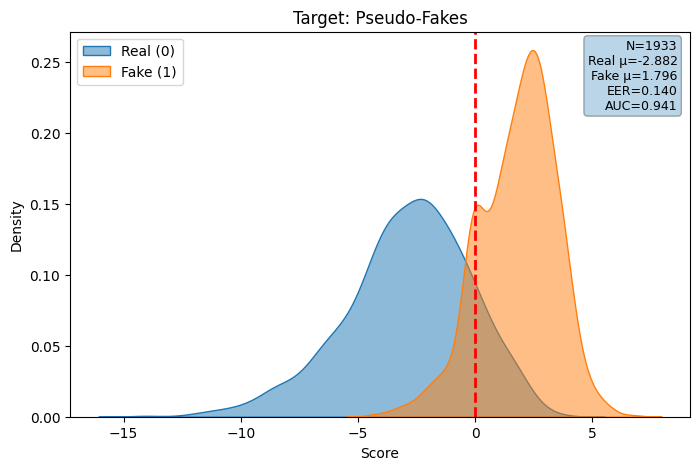

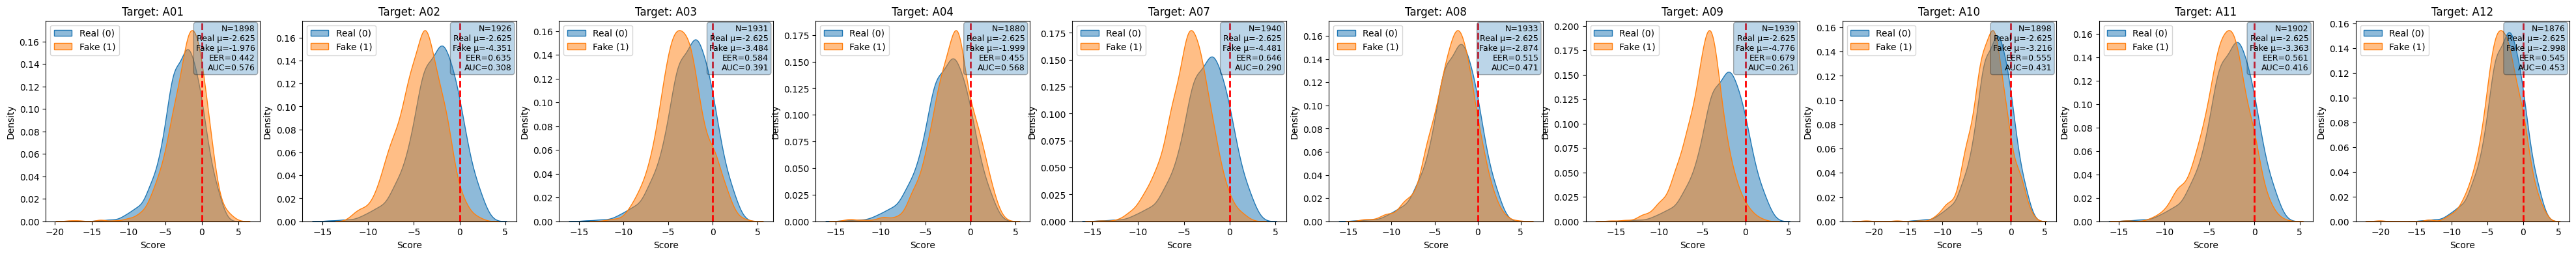

In [6]:
mod = 'flat_pitch'
flat_all_logits, flat_all_labels = show_results(mod)

## F0 inconsistency Expert

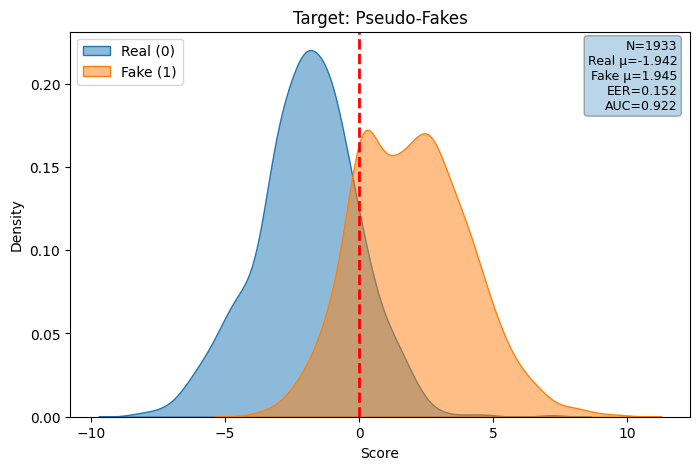

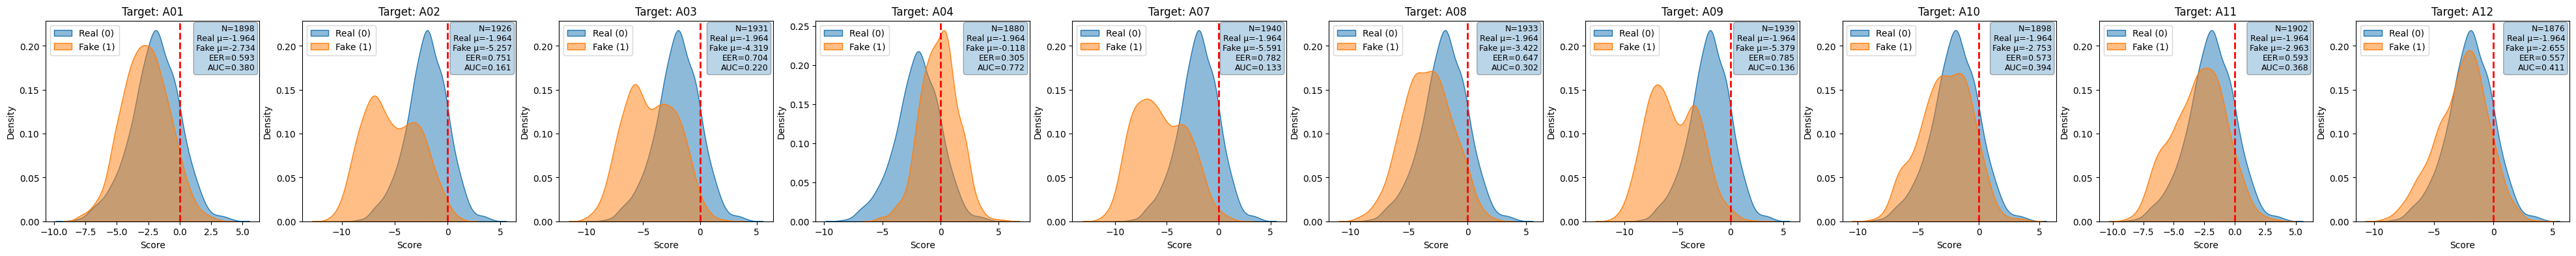

In [7]:
mod = 'f0_incons'
inc_all_logits, inc_all_labels = show_results(mod)

## Oversmoothing Expert
### (still old one)

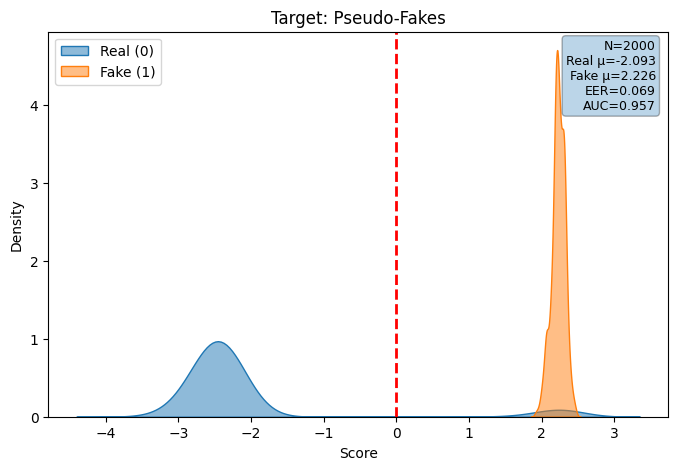

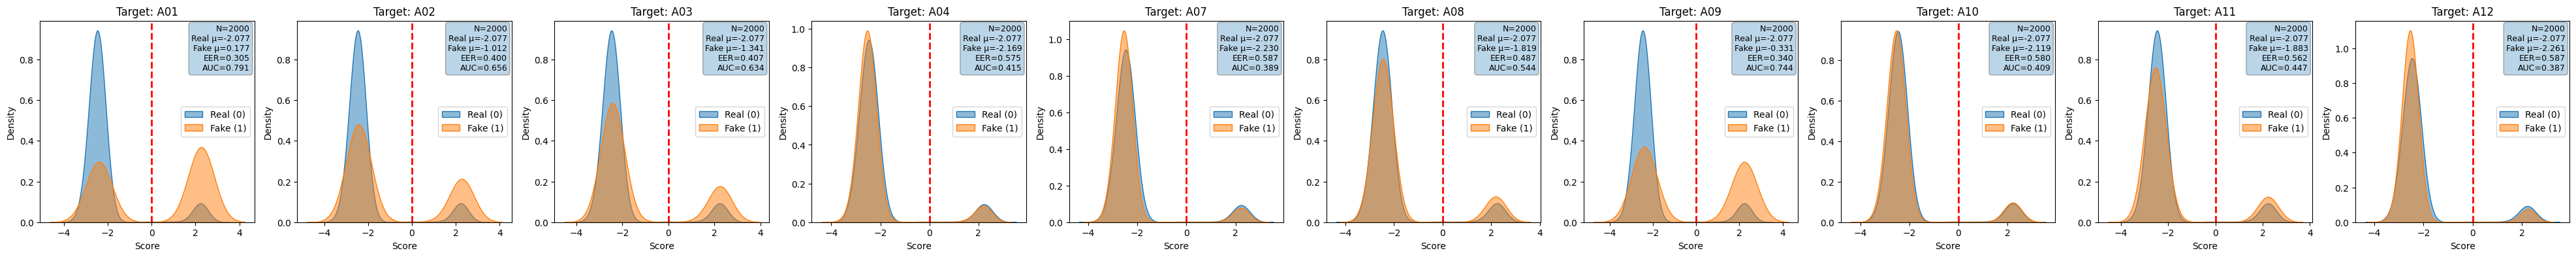

In [8]:
mod = 'oversmooth'
smooth_all_logits, smooth_all_labels = show_results(mod)

## Phase Expert

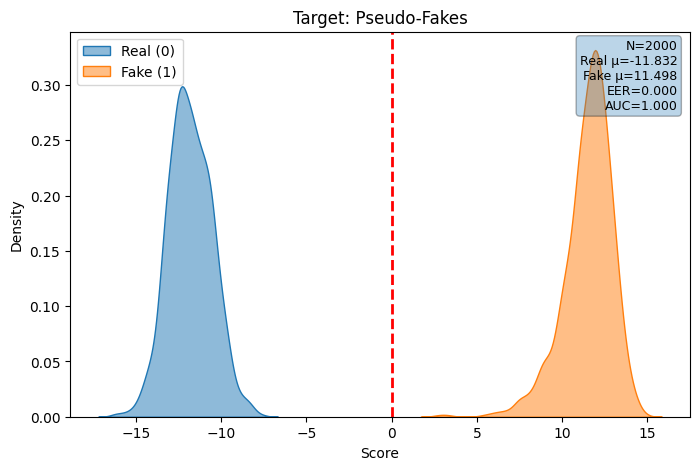

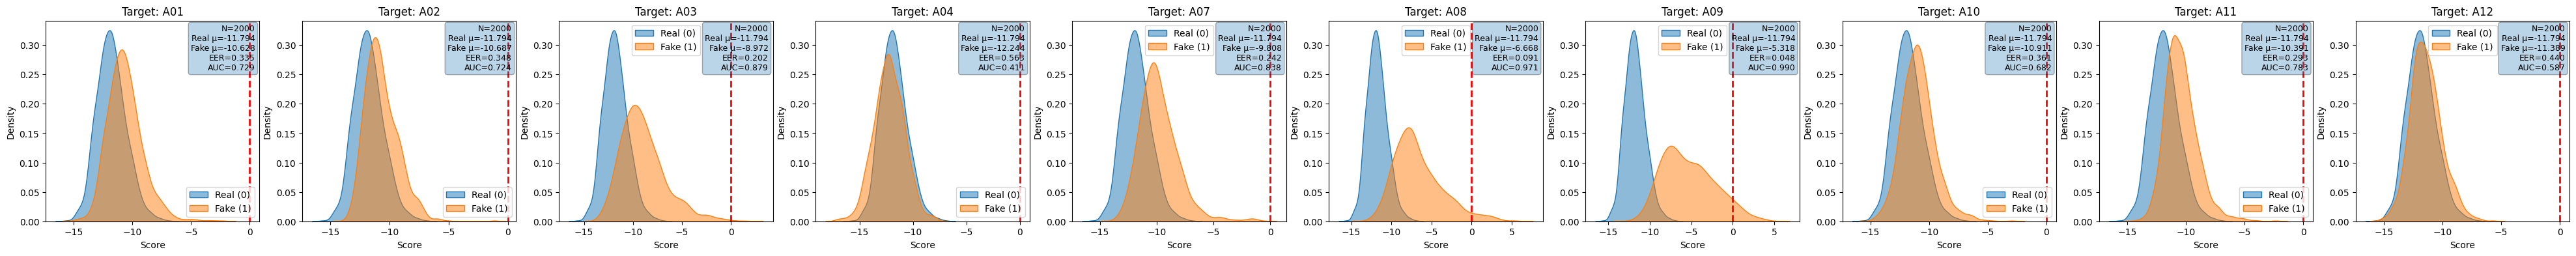

In [9]:
mod = 'min_phase'
phase_all_logits, phase_all_labels = show_results(mod)

# Energy Expert

### (new one, MLP + proxy features)

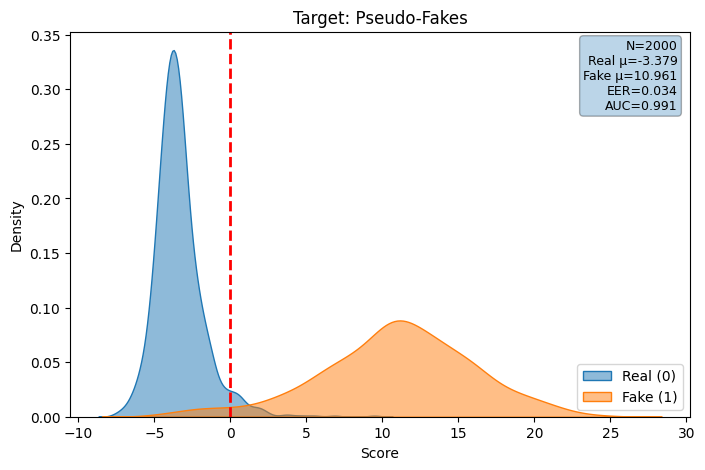

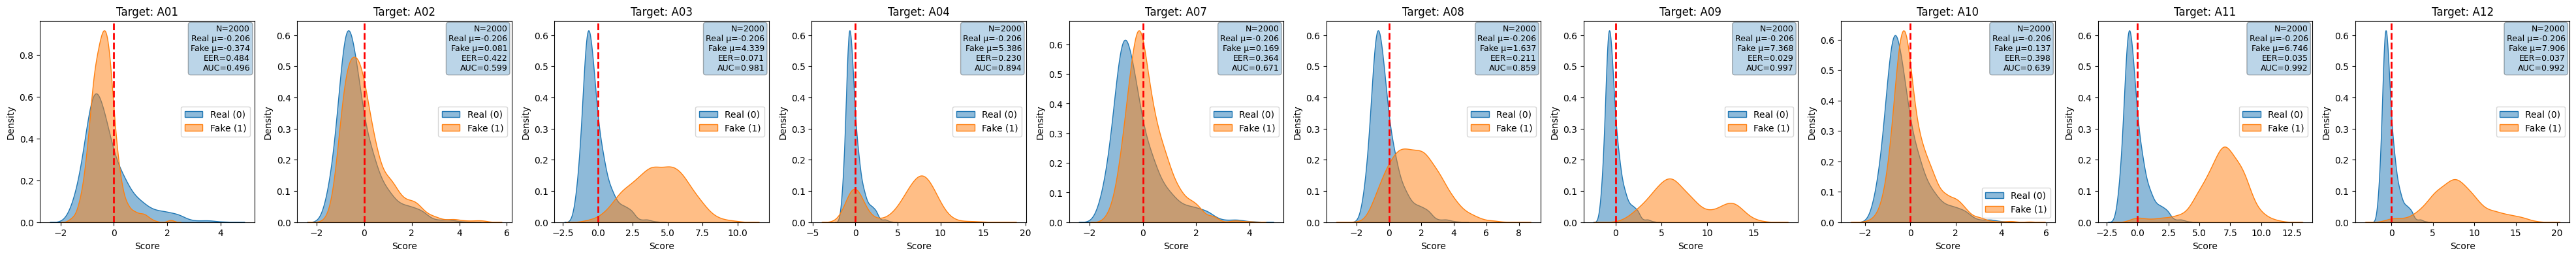

In [11]:
mod = 'energy'
energy_all_logits, energy_all_labels = show_results(mod)

# Inspect tracks 

In [24]:
r = '/Database/ASVspoof2019/public_released_data'
def build_full_path(fname):
    if 'T' in fname:
        base = "LA/ASVspoof2019_LA_train/flac"
    elif 'D' in fname:
        base = "LA/ASVspoof2019_LA_dev/flac"
    else:
        base = "LA/ASVspoof2019_LA_eval/flac"
        
    return os.path.join(r, base, fname + ".flac")

selected_attack = 'A03'
idx = attack_list.index(selected_attack)

p = f'/home/smg/v-viola/moe_antideepfake/results/experts/asv19/energy'
attack_file_IDs = np.load(os.path.join(p, 'TargetCheck', selected_attack, 'file_IDs.npy'))

## Well separated

13
21


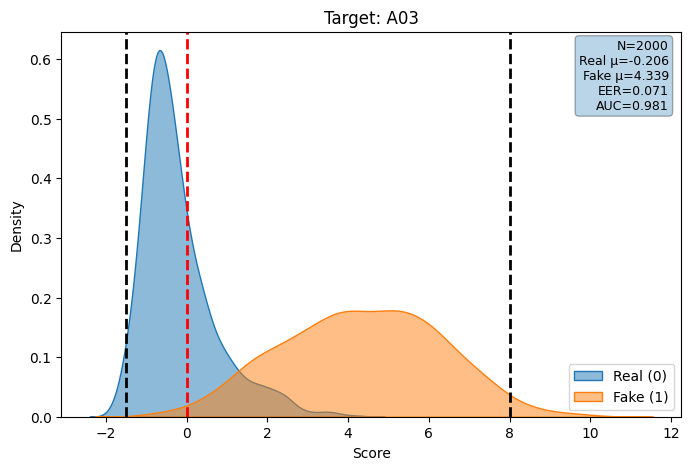

In [31]:
R_THR = -1.5
F_THR = 8

real_files = []
fake_files = []

for i, (logit, label) in enumerate(zip(energy_all_logits[idx], energy_all_labels[idx])):
    if label == 0 and logit < R_THR:
        real_files.append(str(attack_file_IDs[i]))
    elif label == 1 and logit > F_THR:
        fake_files.append(str(attack_file_IDs[i]))

plot_distributions(energy_all_logits[idx], energy_all_labels[idx], attack=selected_attack, F_THR=F_THR, R_THR=R_THR)

real_files_full = [build_full_path(f) for f in real_files]
fake_files_full = [build_full_path(f) for f in fake_files]

print(len(real_files_full))
print(len(fake_files_full))

random.seed(42)
N = 10

real_separated = random.sample(real_files_full, min(N, len(real_files_full)))
fake_separated = random.sample(fake_files_full, min(N, len(fake_files_full)))

## Confused

37
37


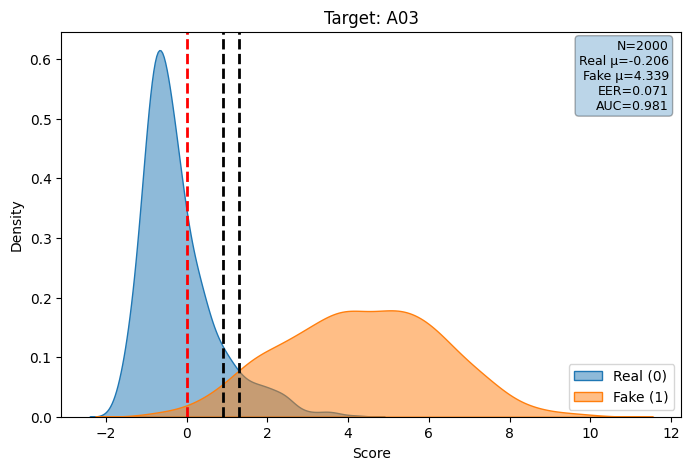

In [47]:
R_THR = 0.9
F_THR = 1.3

real_files = []
fake_files = []
for i, (logit, label) in enumerate(zip(energy_all_logits[idx], energy_all_labels[idx])):
    if label == 0 and R_THR < logit < F_THR:
        real_files.append(str(attack_file_IDs[i]))
        fake_files.append(str(attack_file_IDs[i]))

plot_distributions(energy_all_logits[idx], energy_all_labels[idx], attack=selected_attack, F_THR=F_THR, R_THR=R_THR)

real_files_full = [build_full_path(f) for f in real_files]
fake_files_full = [build_full_path(f) for f in fake_files]

print(len(real_files_full))
print(len(fake_files_full))

random.seed(42)
N = 10

real_confused = random.sample(real_files_full, min(N, len(real_files_full)))
fake_confused = random.sample(fake_files_full, min(N, len(fake_files_full)))

/tmp/ipykernel_2515953/3451863806.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  waveform = torch.tensor(waveform).float()


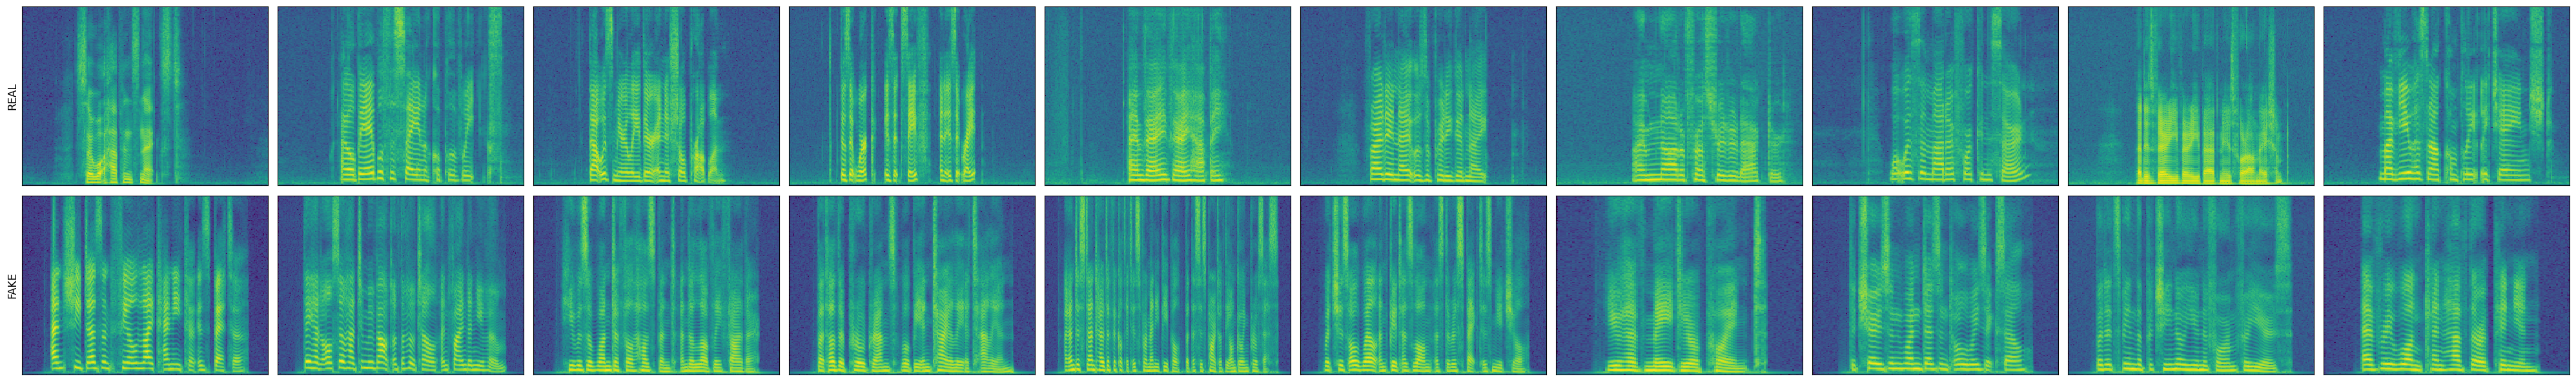

In [ ]:
spec_separated = prepare_spectrograms_from_files(real_separated, fake_separated)
plot_spectrograms_from_arrays(spec_separated, titles=["REAL", "FAKE"], N=N)
print()
print()
spec_confused = prepare_spectrograms_from_files(real_confused, fake_confused)
plot_spectrograms_from_arrays(spec_confused, titles=["REAL", "FAKE"], N=N)